In [5]:
from qiskit_ibm_runtime import QiskitRuntimeService

QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",
    token="Q_HlzWA0RMUylo8b4EYzw8ObdvBo32ebOS6emmgkqbVq",
    instance="crn:v1:bluemix:public:quantum-computing:us-east:a/2fe0497821a84af3af0e9cd9779f889d:28593f40-c19f-47f7-a7cd-d5c8aa10f340::",
    overwrite=True
)

# VQE for H₂: No Mitigation vs TREX — Real QPU (Continuation 76-100)

This notebook **continues** the VQE optimization from iterations 1–75.

- The first 75 iterations were completed in previous notebooks.
- This notebook resumes from the **last converged parameters** of each EM mode.
- Set `max_iter` below to the number of **additional** iterations you want.

## Cell 1 — Imports & Setup

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mapomatic as mm
from scipy.optimize import minimize

from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import efficient_su2
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, EstimatorOptions

service = QiskitRuntimeService()
backend_name = "ibm_kingston"
real_backend = service.backend(backend_name)
print(f"Connected to real QPU backend: {real_backend.name}")

Connected to real QPU backend: ibm_kingston


## Cell 2 — H₂ Hamiltonian & Exact Ground State

In [7]:
H2_op = SparsePauliOp.from_list([
    ("II", -1.052373245772859),
    ("IZ",  0.39793742484318045),
    ("ZI", -0.39793742484318045),
    ("ZZ", -0.01128010425623538),
    ("XX",  0.18093119978423156),
])
observable = H2_op
A = np.array(H2_op.to_matrix())
eigenvalues, _ = np.linalg.eigh(A)
exact_ground_state_energy = min(eigenvalues).real
print(f"Exact ground state energy: {exact_ground_state_energy:.6f} Hartree")

Exact ground state energy: -1.857275 Hartree


## Cell 3 — Ansatz & ISA Transpilation

In [8]:
n_qubits, reps = 2, 1
ansatz = efficient_su2(n_qubits, entanglement="pairwise", reps=reps)

from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
target = real_backend.target
pm = generate_preset_pass_manager(target=target, optimization_level=3)
ansatz_isa = pm.run(ansatz)

rng = np.random.default_rng(42)
test_params = rng.uniform(-np.pi, np.pi, size=ansatz.num_parameters)
test_circ = ansatz.assign_parameters(test_params)
dummy_circ = transpile(test_circ, real_backend, optimization_level=3)
small_circ = mm.deflate_circuit(dummy_circ)
layouts = mm.matching_layouts(small_circ, real_backend)
scores = mm.evaluate_layouts(small_circ, layouts, real_backend)
best_layout = scores[0][0]
print(f"Best physical qubits (mapomatic): {best_layout}")

hamiltonian_isa = observable.apply_layout(ansatz_isa.layout)
print("Hamiltonian mapped to ISA layout successfully")

Best physical qubits (mapomatic): [23, 16]
Hamiltonian mapped to ISA layout successfully


## Cell 4 — EstimatorOptions & VQE Cost Function

In [9]:
def get_estimator_options(em_mode, shots):
    if em_mode == 'none':
        opts = EstimatorOptions(resilience_level=0,
            dynamical_decoupling={"enable": False},
            resilience={"measure_mitigation": False})
    elif em_mode == 'trex':
        opts = EstimatorOptions(resilience_level=0,
            dynamical_decoupling={"enable": False},
            resilience={"measure_mitigation": True})
    else:
        raise ValueError(f"Unknown em_mode: {em_mode}")
    opts.default_shots = shots
    return opts

def vqe_cost_func_qpu(params, ansatz_isa, hamiltonian_isa, backend, em_mode,
                       cost_history_dict, shots):
    pub = (ansatz_isa, [hamiltonian_isa], [params])
    opts = get_estimator_options(em_mode, shots)
    estimator = Estimator(mode=backend, options=opts)
    job = estimator.run(pubs=[pub])
    result = job.result()
    energy = float(result[0].data.evs[0])
    cost_history_dict["iters"] += 1
    cost_history_dict["prev_vector"] = params
    cost_history_dict["cost_history"].append(energy)
    cost_history_dict["param_history"].append(params.copy())
    print(f"Iters. done: {cost_history_dict['iters']} [Current cost: {energy:.6f}]")
    print(f"  Parameters: {params}")
    return energy

print("Functions defined!")

Functions defined!


## Cell 5 — Previous Run Data (75 iterations)

In [10]:
# ========================================================================
# PREVIOUS RUN DATA (iterations 1-75 from notebooks 1, 2, and 3)
# ========================================================================

prev_no_mitigation_costs = [
    -1.3773207870107391,
    -1.3572387571838467,
    -1.4706387378750259,
    -1.4700023893476641,
    -1.526142475397359,
    -1.7178414832581408,
    -1.4251066870414328,
    -1.7057623808191542,
    -1.7346093700820213,
    -1.705457824151177,
    -1.6270059942906598,
    -1.6142274845358497,
    -1.6548051404238449,
    -1.7359773906996552,
    -1.7504690648965218,
    -1.748612711683212,
    -1.75168693203844,
    -1.747601417257452,
    -1.7380599322203467,
    -1.7659868184816494,
    -1.77085222576962,
    -1.7887842229602025,
    -1.792346464586227,
    -1.794455680282641,
    -1.7849938939451868,
    -1.759957,
    -1.537094,
    -1.596225,
    -1.711008,
    -1.722613,
    -1.636147,
    -1.609007,
    -1.721907,
    -1.778097,
    -1.513014,
    -1.776695,
    -1.777991,
    -1.759503,
    -1.780235,
    -1.776172,
    -1.776847,
    -1.776285,
    -1.775338,
    -1.788029,
    -1.778215,
    -1.78115,
    -1.781458,
    -1.780701,
    -1.782513,
    -1.78338,
    -1.7849043250647316,
    -1.5170274401722184,
    -1.5823880019112408,
    -1.7512091690399034,
    -1.7441546753032902,
    -1.6425462229602719,
    -1.6426374850314394,
    -1.7541555331656469,
    -1.7522400681326125,
    -1.5097919579416885,
    -1.7296311056909248,
    -1.7769202411358764,
    -1.74858202315877,
    -1.781887641275134,
    -1.7724718354635178,
    -1.7769318180133964,
    -1.7738668852092654,
    -1.7800855208902289,
    -1.7820045178357613,
    -1.7823451956413312,
    -1.770555202658925,
    -1.7783405816131523,
    -1.776170788576163,
    -1.785805140982999,
    -1.7796401150374,
]

prev_trex_costs = [
    -1.3777973220174324,
    -1.3592209575666225,
    -1.4753292889327139,
    -1.4810016136640867,
    -1.5229383510498276,
    -1.741494332735616,
    -1.452748174286666,
    -1.7489486015324793,
    -1.7245568267110631,
    -1.699668364604829,
    -1.5942782481837334,
    -1.6711287439565878,
    -1.5820097367133035,
    -1.6238261422338616,
    -1.757328404123038,
    -1.7610244351095745,
    -1.7581214865632002,
    -1.7544208450607064,
    -1.7572651904642664,
    -1.7420993079054519,
    -1.7842287563644808,
    -1.8001847902422263,
    -1.806461088102051,
    -1.8026523031174662,
    -1.810724147568568,
    -1.822233,
    -1.579794,
    -1.677986,
    -1.83345,
    -1.8126,
    -1.712354,
    -1.622496,
    -1.822556,
    -1.81729,
    -1.668333,
    -1.744418,
    -1.826967,
    -1.814516,
    -1.834739,
    -1.818608,
    -1.833966,
    -1.841538,
    -1.840212,
    -1.838953,
    -1.834783,
    -1.838172,
    -1.838715,
    -1.837733,
    -1.836559,
    -1.833768,
    -1.8377564671824071,
    -1.4935220922690442,
    -1.685413086375097,
    -1.830855813736759,
    -1.8111109820790314,
    -1.6750287663111871,
    -1.6319694211180331,
    -1.8383563385718587,
    -1.8334672757481267,
    -1.6496015888971556,
    -1.8323450087721314,
    -1.8279492694055637,
    -1.8026643307165136,
    -1.8311487864892717,
    -1.8281721932004646,
    -1.8334193029864803,
    -1.838784088867137,
    -1.8455194894627058,
    -1.8405585207392856,
    -1.845614602610107,
    -1.844215534496776,
    -1.8421693246830075,
    -1.8466306828848058,
    -1.841139179663069,
    -1.8480968290534523,
]

x0_no_mitigation = np.array([2.78538043, 0.404166219, 2.57193756, 0.00113595959, -0.188208338, -2.84994683, -1.81250608, 0.85900667])
x0_trex = np.array([2.92311222, 0.49589421, 4.86327907, -0.13441314, 0.06758809, -2.60211256, 0.25503626, -1.18230679])

print("Previous run data loaded!")
print(f"  No Mitigation: {len(prev_no_mitigation_costs)} iters, last energy = {prev_no_mitigation_costs[-1]:.6f}")
print(f"  TREX Only:     {len(prev_trex_costs)} iters, last energy = {prev_trex_costs[-1]:.6f}")


Previous run data loaded!
  No Mitigation: 75 iters, last energy = -1.779640
  TREX Only:     75 iters, last energy = -1.848097


## Cell 6 — Continue VQE (iterations 76–100)

We resume VQE from the last converged parameters of each EM mode.

In [11]:
shots = 10000
max_iter = 25

em_configs = [("No Mitigation", "none"), ("TREX Only", "trex")]
warm_starts = {
    "No Mitigation": (x0_no_mitigation, prev_no_mitigation_costs),
    "TREX Only":     (x0_trex,          prev_trex_costs),
}
prev_iter_count = len(prev_no_mitigation_costs)  # = 75

print(f"Resuming from iteration: {prev_iter_count}")
print("=" * 70)

all_results = {}
all_histories = {}

for label, em_mode in em_configs:
    x0, prev_costs = warm_starts[label]
    print(f"\nContinuing VQE with: {label}")
    print(f"  Warm-start energy: {prev_costs[-1]:.6f}")

    cost_history = {
        "prev_vector": None,
        "iters": prev_iter_count,
        "cost_history": [],
        "param_history": [],
    }

    res = minimize(
        vqe_cost_func_qpu, x0,
        args=(ansatz_isa, hamiltonian_isa, real_backend, em_mode, cost_history, shots),
        method="cobyla",
        options={"maxiter": max_iter},
    )

    combined_costs = list(prev_costs) + cost_history["cost_history"]
    all_results[label] = {
        "converged_energy": combined_costs[-1],
        "nfev": len(combined_costs),
        "success": res.success,
        "message": res.message,
        "all_costs": combined_costs,
    }
    all_histories[label] = combined_costs

    print(f"  Converged Energy: {combined_costs[-1]:.6f}")
    print(f"  Error: {abs(combined_costs[-1] - exact_ground_state_energy):.6f}")
    print(f"  Total Iterations: {len(combined_costs)}")

print("\nAll VQE continuation runs completed!")

Resuming from iteration: 75

Continuing VQE with: No Mitigation
  Warm-start energy: -1.779640
Iters. done: 76 [Current cost: -1.773586]
  Parameters: [ 2.78538043e+00  4.04166219e-01  2.57193756e+00  1.13595959e-03
 -1.88208338e-01 -2.84994683e+00 -1.81250608e+00  8.59006670e-01]
Iters. done: 77 [Current cost: -1.518972]
  Parameters: [ 3.78538043e+00  4.04166219e-01  2.57193756e+00  1.13595959e-03
 -1.88208338e-01 -2.84994683e+00 -1.81250608e+00  8.59006670e-01]
Iters. done: 78 [Current cost: -1.589067]
  Parameters: [ 2.78538043e+00  1.40416622e+00  2.57193756e+00  1.13595959e-03
 -1.88208338e-01 -2.84994683e+00 -1.81250608e+00  8.59006670e-01]
Iters. done: 79 [Current cost: -1.744480]
  Parameters: [ 2.78538043e+00  4.04166219e-01  3.57193756e+00  1.13595959e-03
 -1.88208338e-01 -2.84994683e+00 -1.81250608e+00  8.59006670e-01]
Iters. done: 80 [Current cost: -1.743767]
  Parameters: [ 2.78538043  0.40416622  2.57193756  1.00113596 -0.18820834 -2.84994683
 -1.81250608  0.85900667]
It

## Cell 7 — Convergence Plot (Full History)

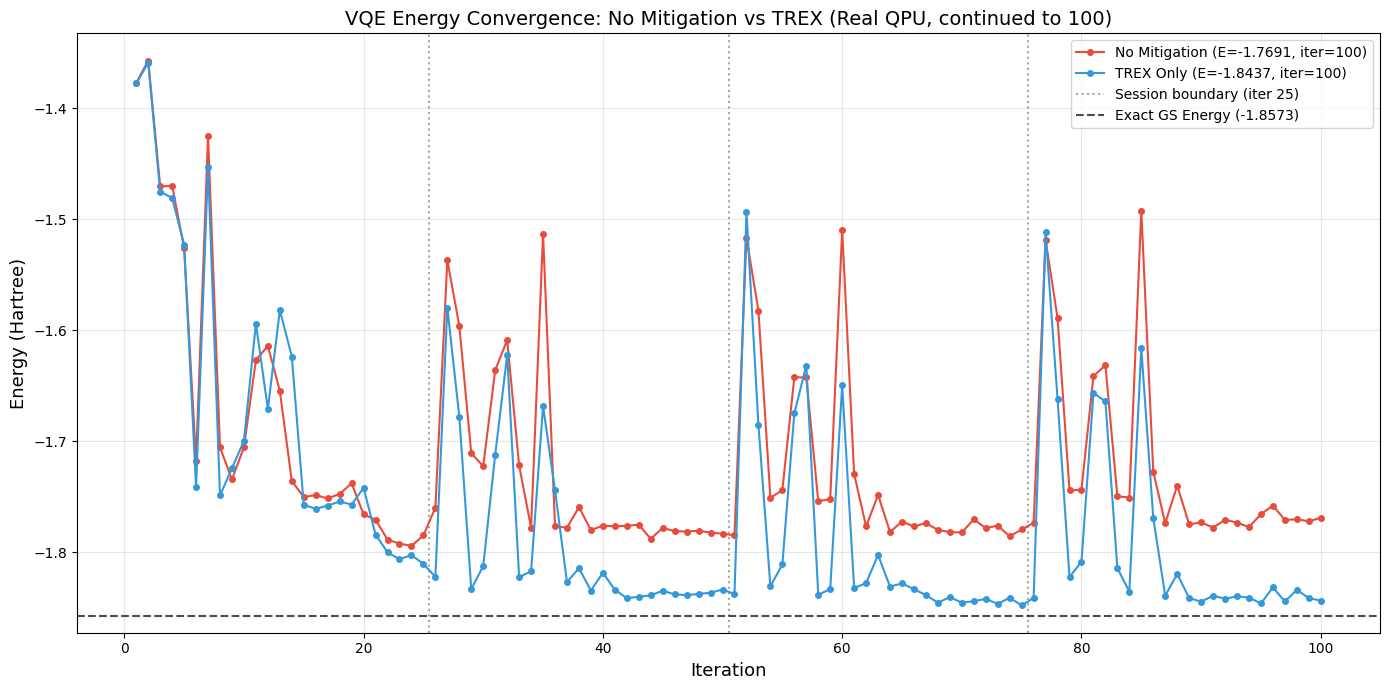

In [12]:
colors = ['#e74c3c', '#3498db']
fig, ax = plt.subplots(figsize=(14, 7))

for idx, (label, _) in enumerate(em_configs):
    costs = all_histories[label]
    total = len(costs)
    ax.plot(range(1, total+1), costs, marker='o', markersize=4,
           label=f"{label} (E={costs[-1]:.4f}, iter={total})",
           color=colors[idx], linewidth=1.5)

# Session boundaries
for boundary in [25, 50, 75]:
    ax.axvline(x=boundary+0.5, color='gray', linestyle=':', linewidth=1.5,
               alpha=0.7, label=f'Session boundary (iter {boundary})' if boundary == 25 else None)

ax.axhline(y=exact_ground_state_energy, color='black', linestyle='--',
           linewidth=1.5, alpha=0.7,
           label=f'Exact GS Energy ({exact_ground_state_energy:.4f})')

ax.set_xlabel("Iteration", fontsize=13)
ax.set_ylabel("Energy (Hartree)", fontsize=13)
ax.set_title("VQE Energy Convergence: No Mitigation vs TREX (Real QPU, continued to 100)", fontsize=14)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Cell 8 — Summary Table & Bar Chart

,EM Technique,Converged Energy,Exact Energy,Error,% Error,Total Iterations,Converged?
0,No Mitigation,-1.769106,-1.857275,0.088169,4.75%,100,False
1,TREX Only,-1.843743,-1.857275,0.013532,0.73%,100,False


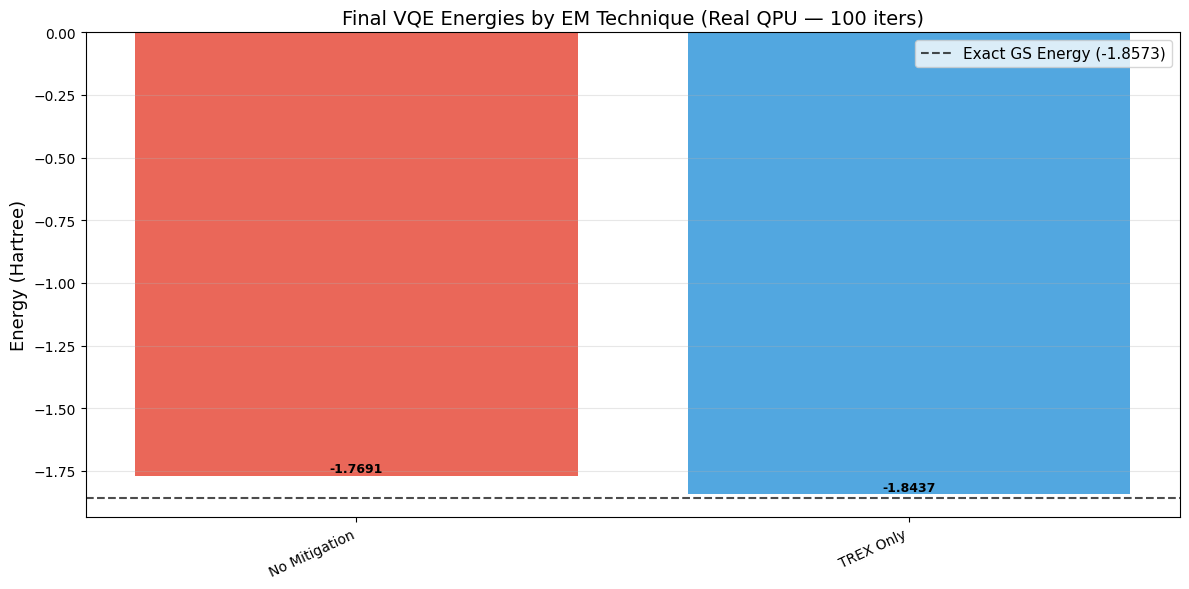

In [13]:
rows = []
for label, _ in em_configs:
    ce = all_results[label]["converged_energy"]
    error = abs(ce - exact_ground_state_energy)
    pct_error = 100 * error / abs(exact_ground_state_energy)
    rows.append({
        "EM Technique": label,
        "Converged Energy": f"{ce:.6f}",
        "Exact Energy": f"{exact_ground_state_energy:.6f}",
        "Error": f"{error:.6f}",
        "% Error": f"{pct_error:.2f}%",
        "Total Iterations": all_results[label]["nfev"],
        "Converged?": all_results[label]["success"],
    })

df = pd.DataFrame(rows)
display(df)

fig, ax = plt.subplots(figsize=(12, 6))
labels = [r["EM Technique"] for r in rows]
energies = [all_results[l]["converged_energy"] for l, _ in em_configs]
bars = ax.bar(range(len(labels)), energies, color=colors, alpha=0.85)
ax.axhline(y=exact_ground_state_energy, color='black', linestyle='--', linewidth=1.5, alpha=0.7,
           label=f'Exact GS Energy ({exact_ground_state_energy:.4f})')
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=25, ha='right', fontsize=10)
ax.set_ylabel("Energy (Hartree)", fontsize=13)
ax.set_title("Final VQE Energies by EM Technique (Real QPU — 100 iters)", fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, axis='y', alpha=0.3)
for bar, e in zip(bars, energies):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f'{e:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

## Cell 9 — Inspect Full Results

In [14]:
all_results

{'No Mitigation': {'converged_energy': -1.769106323337632,
  'nfev': 100,
  'success': False,
  'message': 'Return from COBYLA because the objective function has been evaluated MAXFUN times.',
  'all_costs': [-1.3773207870107391,
   -1.3572387571838467,
   -1.4706387378750259,
   -1.4700023893476641,
   -1.526142475397359,
   -1.7178414832581408,
   -1.4251066870414328,
   -1.7057623808191542,
   -1.7346093700820213,
   -1.705457824151177,
   -1.6270059942906598,
   -1.6142274845358497,
   -1.6548051404238449,
   -1.7359773906996552,
   -1.7504690648965218,
   -1.748612711683212,
   -1.75168693203844,
   -1.747601417257452,
   -1.7380599322203467,
   -1.7659868184816494,
   -1.77085222576962,
   -1.7887842229602025,
   -1.792346464586227,
   -1.794455680282641,
   -1.7849938939451868,
   -1.759957,
   -1.537094,
   -1.596225,
   -1.711008,
   -1.722613,
   -1.636147,
   -1.609007,
   -1.721907,
   -1.778097,
   -1.513014,
   -1.776695,
   -1.777991,
   -1.759503,
   -1.780235,
   -1.77

In [15]:
all_histories

{'No Mitigation': [-1.3773207870107391,
  -1.3572387571838467,
  -1.4706387378750259,
  -1.4700023893476641,
  -1.526142475397359,
  -1.7178414832581408,
  -1.4251066870414328,
  -1.7057623808191542,
  -1.7346093700820213,
  -1.705457824151177,
  -1.6270059942906598,
  -1.6142274845358497,
  -1.6548051404238449,
  -1.7359773906996552,
  -1.7504690648965218,
  -1.748612711683212,
  -1.75168693203844,
  -1.747601417257452,
  -1.7380599322203467,
  -1.7659868184816494,
  -1.77085222576962,
  -1.7887842229602025,
  -1.792346464586227,
  -1.794455680282641,
  -1.7849938939451868,
  -1.759957,
  -1.537094,
  -1.596225,
  -1.711008,
  -1.722613,
  -1.636147,
  -1.609007,
  -1.721907,
  -1.778097,
  -1.513014,
  -1.776695,
  -1.777991,
  -1.759503,
  -1.780235,
  -1.776172,
  -1.776847,
  -1.776285,
  -1.775338,
  -1.788029,
  -1.778215,
  -1.78115,
  -1.781458,
  -1.780701,
  -1.782513,
  -1.78338,
  -1.7849043250647316,
  -1.5170274401722184,
  -1.5823880019112408,
  -1.7512091690399034,
  -